# Anàlisi d'Ocupació d'Aules (Nivell 1)
Aquest quadern crea el mapa de calor d'ocupació de cada aula per dia i franja.

**Novetat d'aquesta versió**: Les hores s'agrupen en rangs tancats d'1 hora (ex: `08:00 - 09:00`). Així s'evita tenir columnes soltes per a classes que comencen a i quart (:15) o a la mitja (:30). L'script arrodoneix l'hora d'inici i calcula quants blocs d'1 hora ocupa segons la durada de la classe.

Generant mapa de calor pel 1r Semestre...


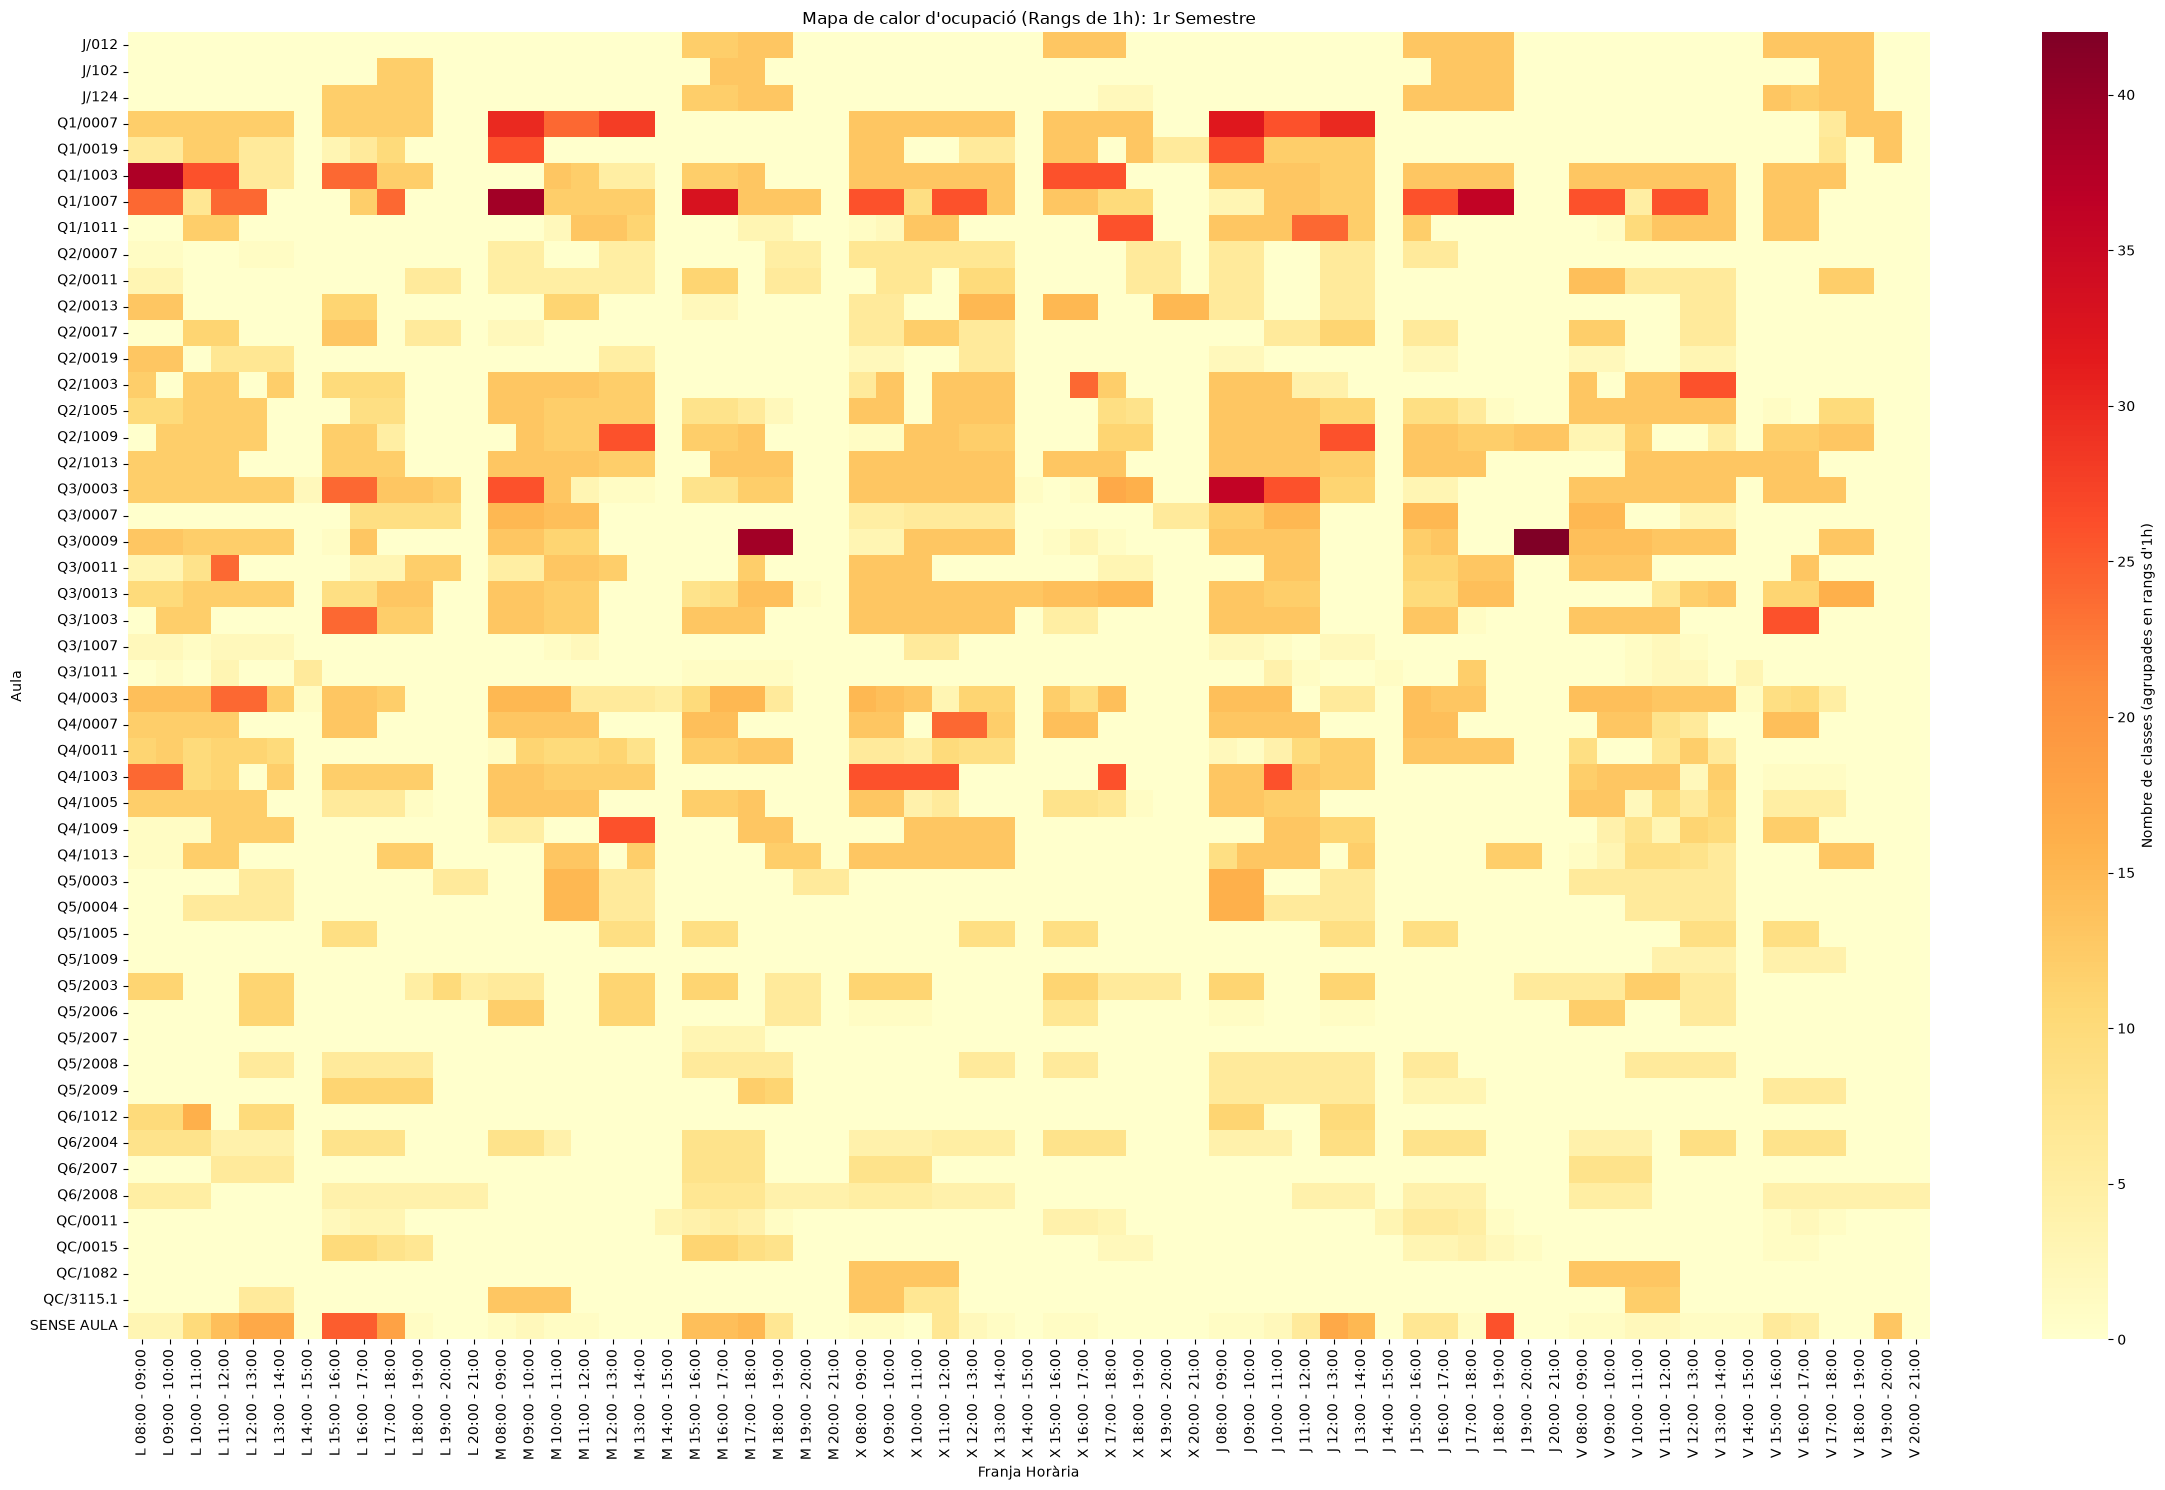

Generant mapa de calor pel 2n Semestre...


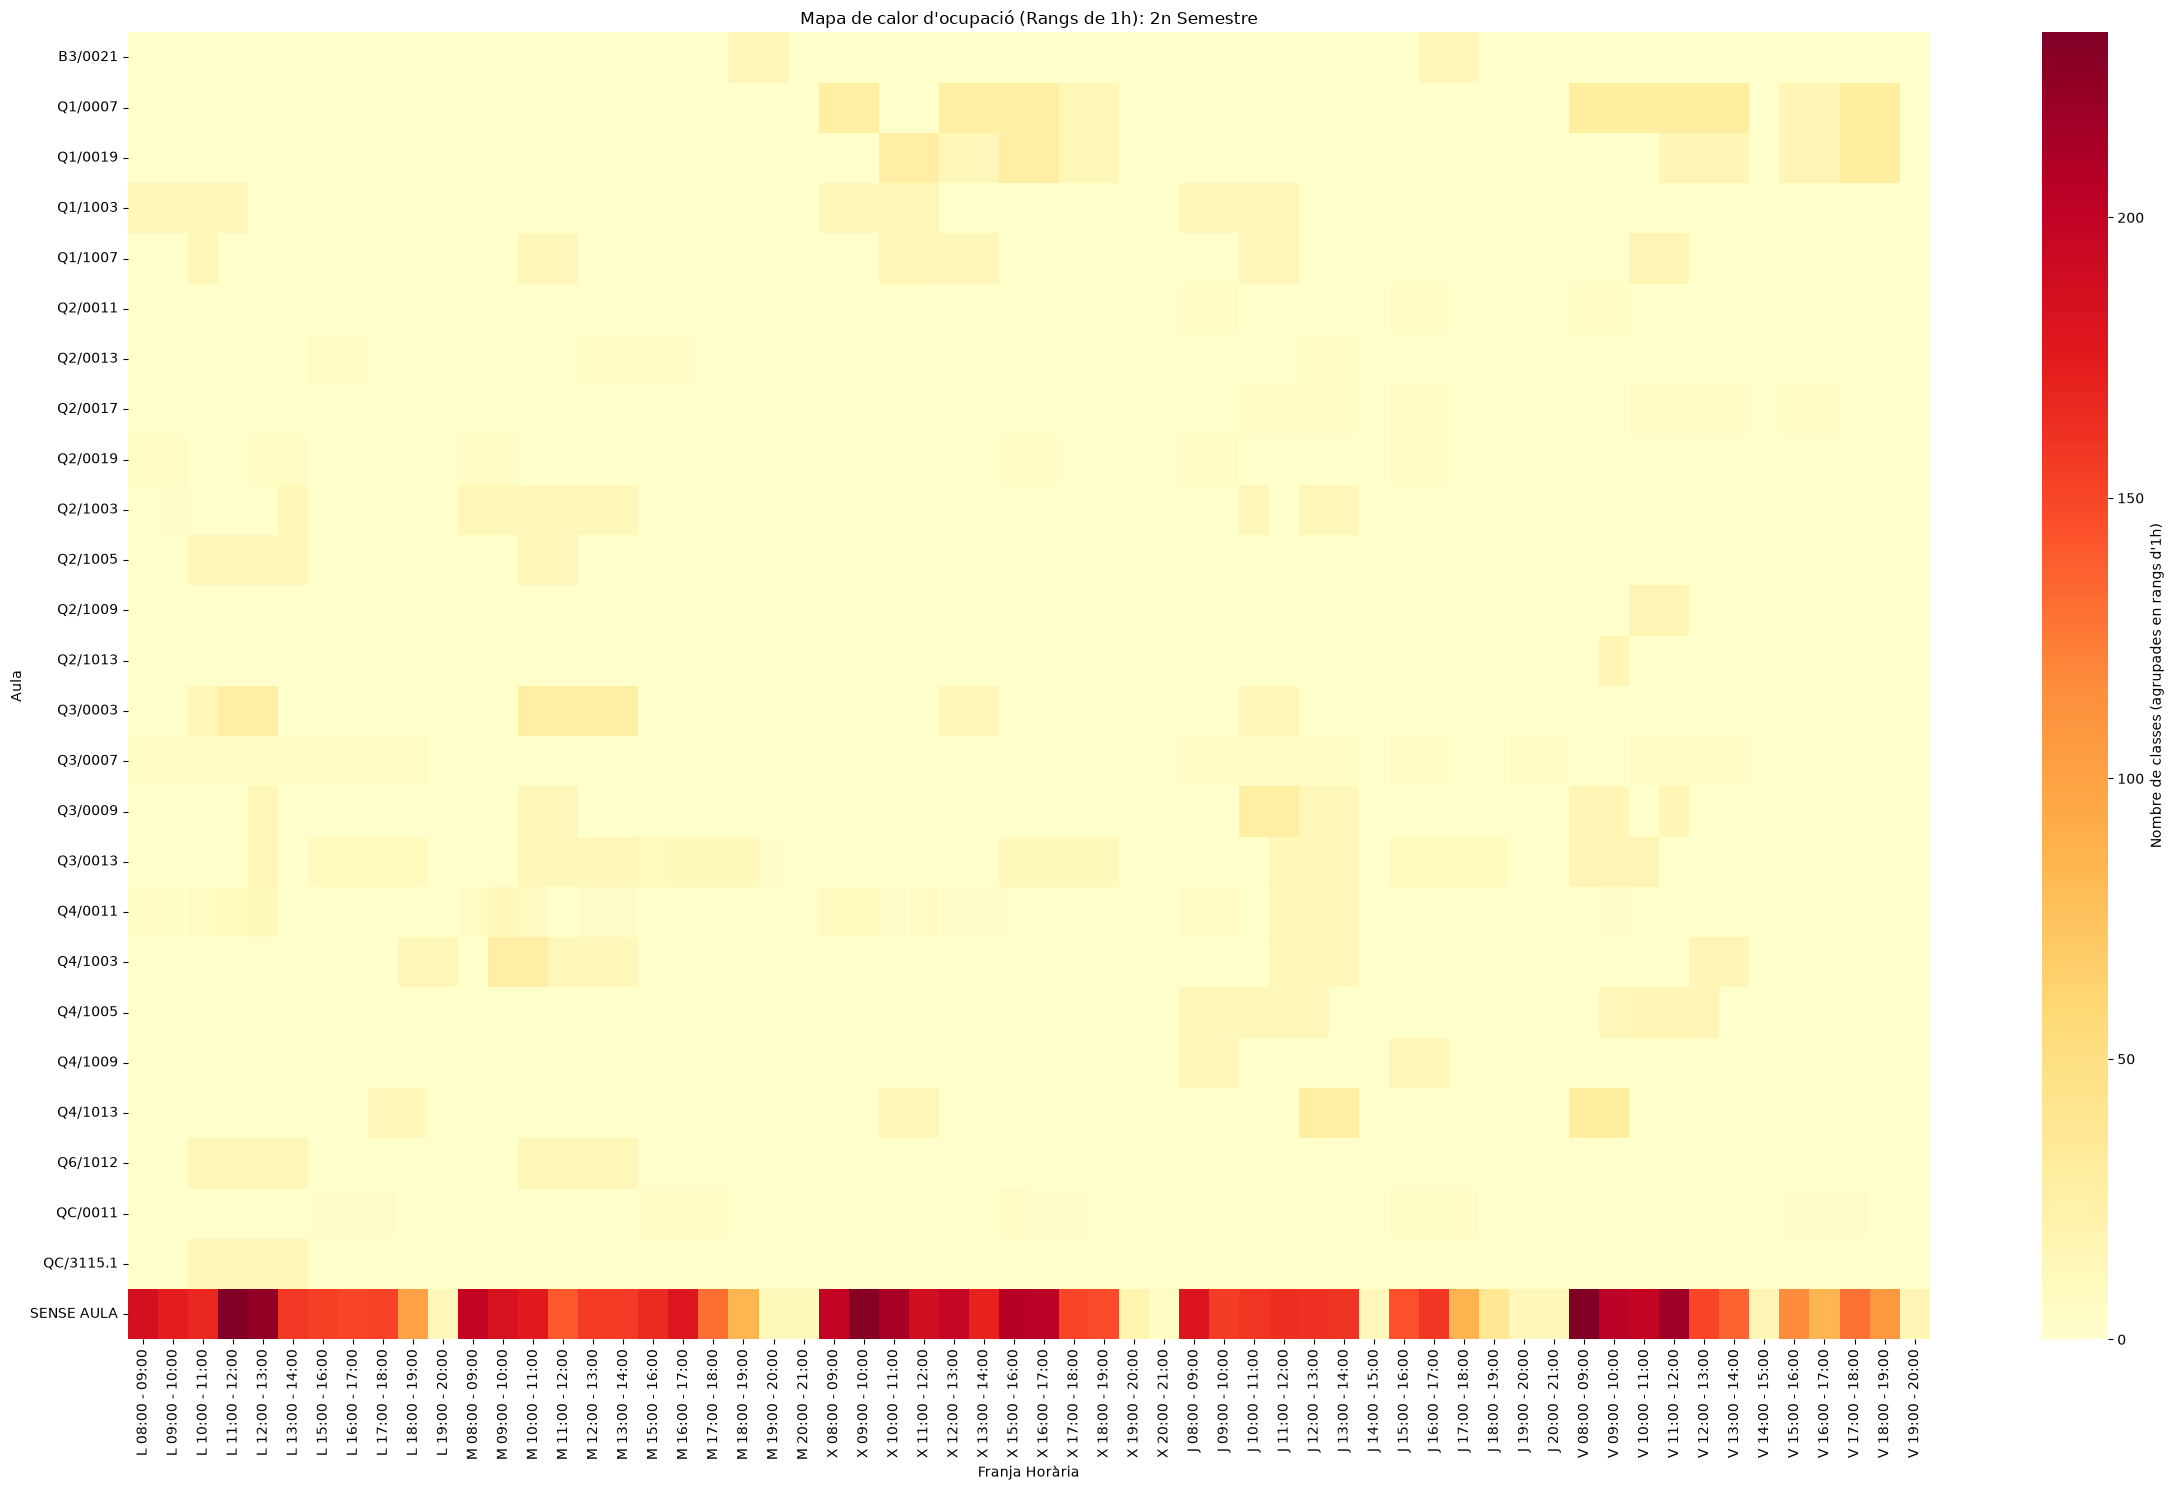

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar dades
sessions = pd.read_csv('sessions.csv')

# Neteja de dades: tractar sessions sense aula
sessions['aula_plot'] = sessions['aula_partida'].fillna('SENSE AULA')

def obtenir_blocs_horaris_rangs(row):
    """
    Arrodoneix l'hora a la baixa i genera els rangs de 1h que ocupa la classe.
    Exemple: 08:15 amb durada 120min -> ['08:00 - 09:00', '09:00 - 10:00']
    """
    try:
        # Agafar l'hora d'inici i arrodonir a l'hora en punt
        start = pd.to_datetime(str(row['h_ini']), format='%H:%M').floor('h')
        
        # Calcular el nombre de blocs d'1 hora segons la durada_min
        durada = int(row['durada_min'])
        num_blocs = max(1, round(durada / 60.0))
        
        # Generar els blocs
        slots = pd.date_range(start, periods=num_blocs, freq='1h')
        
        # Formatejar com a text 'HH:00 - HH:00'
        return [(t.strftime('%H:00') + " - " + (t + pd.Timedelta(hours=1)).strftime('%H:00')) for t in slots]
    except Exception as e:
        # Si falla (ex: dades mal formades), retornem el valor original
        return [str(row['h_ini'])]

def plot_heatmap(semestre_codi, titol):
    df_semestre = sessions[sessions['semestre'] == semestre_codi].copy()
    
    # Expandir cada sessió als seus rangs corresponents
    df_semestre['rangs_ocupats'] = df_semestre.apply(obtenir_blocs_horaris_rangs, axis=1)
    df_expanded = df_semestre.explode('rangs_ocupats')
    
    # Agrupar per aula, dia i rang
    ocupacio = df_expanded.groupby(['aula_plot', 'dia', 'rangs_ocupats']).size().reset_index(name='sessions')
    
    # Establir l'ordre correcte dels dies de la setmana
    dies_ordre = ['L', 'M', 'X', 'J', 'V']
    ocupacio['dia'] = pd.Categorical(ocupacio['dia'], categories=dies_ordre, ordered=True)
    
    # Ordenar el dataframe per dia i després per rang
    ocupacio = ocupacio.sort_values(['dia', 'rangs_ocupats'])
    
    # Crear una clau combinada per l'eix X (Dia + Rang Horari)
    ocupacio['franja_eix'] = ocupacio['dia'].astype(str) + " " + ocupacio['rangs_ocupats']
    
    # Guardar l'ordre exacte de les franges per reindexar després del pivot
    ordre_franges = ocupacio['franja_eix'].unique()
    
    # Pivotar per format heatmap
    pivot_df = ocupacio.pivot(index='aula_plot', columns='franja_eix', values='sessions').fillna(0)
    
    # Reindexar per mantenir l'ordre cronològic (L -> V, matí -> vespre)
    pivot_df = pivot_df.reindex(columns=ordre_franges)
    
    # Dibuixar
    plt.figure(figsize=(24, 15))
    sns.heatmap(pivot_df, cmap='YlOrRd', cbar_kws={'label': 'Nombre de classes (agrupades en rangs d\'1h)'})
    plt.title(f'Mapa de calor d\'ocupació (Rangs de 1h): {titol}')
    plt.xlabel('Franja Horària')
    plt.ylabel('Aula')
    plt.tight_layout()
    plt.show()

# Executar per al primer i segon semestre
print("Generant mapa de calor pel 1r Semestre...")
plot_heatmap('C/1', '1r Semestre')

print("Generant mapa de calor pel 2n Semestre...")
plot_heatmap('C/2', '2n Semestre')
